### Load an Ontix model and generate embeddings from cells from hold-out set

In [1]:
#### Definitions #####
import numpy as np
import os
import sys
import pandas as pd
import pickle
import autoencodix as acx
import json


def keep_features_from_acxcontainer(acx_container, feature_ids_to_keep):	

	for split in ['train', 'valid', 'test']:
		if getattr(acx_container, split) is None:
			continue

		dataset = getattr(acx_container, split)
		feature_id_array = np.array(dataset.feature_ids)
		keep_indices = [i for i, fid in enumerate(feature_id_array) if fid in feature_ids_to_keep]

		dataset.data = dataset.data[:, keep_indices]
		dataset.feature_ids = [dataset.feature_ids[i] for i in keep_indices]
		setattr(acx_container, split, dataset)

	return acx_container



data_final_folder = "../data/large_sc_data/"
results_folder = "../results/large_ontix_save/run_Aug26/"
llm_ontology_folder = "../data/llm_ontologies/final_ontologies/"

ontix_model = "Dim32_ClaudeOpus5"


file_holdout = os.path.join(data_final_folder, f"census-acxcontainer_holdout.pkl")

final_ontix_model_file = os.path.join(results_folder, f"large_ontix_final_model_{ontix_model}.pkl")


#### Step 1 - Load and predict on holdout set #####
print("Loading holdout data ...")
with open(file_holdout, "rb") as f:
	acx_container = pickle.load(f)

print("Preparing holdout data for feature size per ontology ...")
ont_files = [
	# Order from Latent Dim -> Hidden Dim -> Input Dim
	os.path.join(llm_ontology_folder, f"{ontix_model}_ontology__ensembl_level1.tsv"),
	os.path.join(llm_ontology_folder, f"{ontix_model}_ontology__ensembl_level2.tsv"),
	]

ont_lvl2 = pd.read_csv(ont_files[1], sep='\t', usecols=[0], header=None)
ont_lvl2.columns = ['feature_id']

acx_container = keep_features_from_acxcontainer(acx_container, ont_lvl2['feature_id'].values)

# #####  Expand metadata with cell type tasks ###################
with open("../data/gemini_celltype_tasks2.json", "r") as f:
    gemini_celltype_tasks2 = json.load(f)


# Downsample only for cells from lung tissue 
lung_sample_ids = acx_container.test.metadata[acx_container.test.metadata['tissue'] == 'lung'].index
# Get integer indices of these sample IDs
lung_indices = [i for i, sid in enumerate(acx_container.test.sample_ids) if sid in lung_sample_ids]
acx_container.test.data = acx_container.test.data[lung_indices, :]
acx_container.test.sample_ids = acx_container.test.sample_ids[lung_indices]
acx_container.test.metadata = acx_container.test.metadata.loc[acx_container.test.sample_ids, :]
print(f"Holdout test set size after downsampling to lung tissue: {acx_container.test.data.shape[0]} samples.")


print("Loading trained model ...")
loaded_ontix = acx.Ontix.load(file_path=final_ontix_model_file)
loaded_ontix._trainer._config.save_vram = True  # Enable memory saving for prediction on holdout set
loaded_ontix._trainer._config.batch_size = 5000  
loaded_ontix._trainer._config.device = "cpu"

print("Predicting on holdout data ...")
result = loaded_ontix.predict(
	data= acx_container
)


Loading holdout data ...
Preparing holdout data for feature size per ontology ...
Holdout test set size after downsampling to lung tissue: 13083 samples.
Loading trained model ...
Attempting to load a pipeline from ../results/large_ontix_save/run_Aug26/large_ontix_final_model_Dim32_ClaudeOpus5.pkl...
Pipeline object loaded successfully. Actual type: Ontix
Preprocessor loaded successfully.
Predicting on holdout data ...


## Use case lung adenocarcinoma vs. healthy (normal) lung cells

### Determine latent dimensions with biggest differences across groups

In [2]:
# Get the latent space as df
df_latent = loaded_ontix.result.get_latent_df(split="test", epoch=-1)

# Define groups for comparison 
anno_col = "disease"
group1 = "lung adenocarcinoma"
group2 = "normal"

samples_group1 = loaded_ontix.result.new_datasets.test.metadata[loaded_ontix.result.new_datasets.test.metadata[anno_col] == group1].index.tolist()
samples_group2 = loaded_ontix.result.new_datasets.test.metadata[loaded_ontix.result.new_datasets.test.metadata[anno_col] == group2].index.tolist()

print(f"Number of samples in {group1}: {len(samples_group1)}")
print(f"Number of samples in {group2}: {len(samples_group2)}")

Number of samples in lung adenocarcinoma: 1193
Number of samples in normal: 7213


In [3]:
# Calculate latent dimension means for the two groups
group1_means = df_latent.loc[samples_group1].mean()
group2_means = df_latent.loc[samples_group2].mean()
# print direct comparison of means for the two groups
comparison_df = pd.DataFrame({
	'Group 1 Mean': group1_means,
	'Group 2 Mean': group2_means
})

# Sort by biggest difference in means
comparison_df['Mean Difference'] = (group1_means - group2_means).abs()
comparison_df = comparison_df.sort_values(by='Mean Difference', ascending=False)
print(comparison_df.head(10))

                                          Group 1 Mean  Group 2 Mean  \
dim01_energy_metabolism_oxidative             1.499958     22.871981   
dim24_adaptive_immunity_antigen              41.247013     20.482565   
dim11_secretory_pathway_glycosylation        27.988789     19.789919   
dim25_redox_oxidative_stress                 18.780905     26.506630   
dim15_apoptosis_cell_death                   45.986591     39.371037   
dim10_protein_degradation_autophagy          40.985203     34.602951   
dim28_endocrine_hormone_signaling            29.180212     23.330484   
dim23_innate_immunity_inflammation           29.358109     24.135984   
dim02_glycolytic_fermentative_metabolism     19.356283     24.429338   
dim17_developmental_morphogen_signaling      26.708681     21.794252   

                                          Mean Difference  
dim01_energy_metabolism_oxidative               21.372023  
dim24_adaptive_immunity_antigen                 20.764448  
dim11_secretory_pathway_gly

In [ ]:
groups_list = [
    group1,
    group2,
]

# Perform Linear Discriminant Analysis (LDA) to find the latent dimension that best separates the groups
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_validate


scores = {}
# for each latent dimension
for latent_dim in df_latent.columns:
	lda = LinearDiscriminantAnalysis()
	X = df_latent[latent_dim].values.reshape(-1, 1)
	y = loaded_ontix.result.new_datasets.test.metadata[anno_col].values
	# Reduce x and y to only include samples from the groups of interest
	mask = np.isin(y, groups_list)
	X = X[mask]
	y = y[mask]
	metric = "roc_auc_ovo"
 	# Do CV-5 fold cross-validation and calculate the AUC-ROC score for this latent dimension
	scores[latent_dim] = cross_validate(lda, X, y, cv=5, scoring=metric, return_train_score=True, n_jobs=-1)

scores_df = pd.DataFrame({
	'latent_dim': list(scores.keys()),
	'test_score_mean': [scores[ld]['test_score'].mean() for ld in scores.keys()],
	'test_score_std': [scores[ld]['test_score'].std() for ld in scores.keys()],
	'train_score_mean': [scores[ld]['train_score'].mean() for ld in scores.keys()],
	'train_score_std': [scores[ld]['train_score'].std() for ld in scores.keys()],
})
scores_df = scores_df.sort_values(by='test_score_mean', ascending=False)
print(scores_df)

                                     latent_dim  test_score_mean  \
0             dim01_energy_metabolism_oxidative         0.850838   
23              dim24_adaptive_immunity_antigen         0.788262   
24                 dim25_redox_oxidative_stress         0.770972   
10        dim11_secretory_pathway_glycosylation         0.716187   
22           dim23_innate_immunity_inflammation         0.675404   
27            dim28_endocrine_hormone_signaling         0.661519   
1      dim02_glycolytic_fermentative_metabolism         0.659820   
4                   dim05_nucleotide_metabolism         0.623074   
25              dim26_xenobiotic_detoxification         0.601490   
12            dim13_dna_repair_genome_stability         0.594020   
15                dim16_growth_factor_signaling         0.590337   
28        dim29_gpcr_second_messenger_signaling         0.587306   
31           dim32_circadian_and_temporal_state         0.586790   
16      dim17_developmental_morphogen_signaling 

### Plot top latent dimensions as KDE plots over groups

[(-20.0, 125.0), (-20.0, 125.0)]

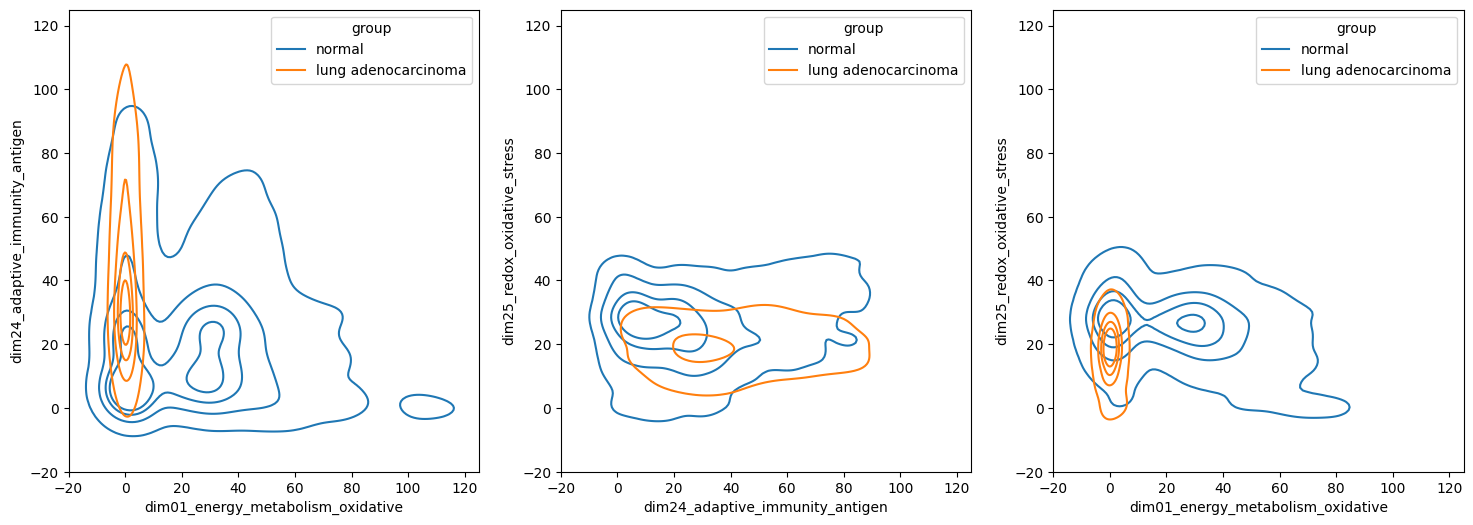

In [10]:
import seaborn as sns
from matplotlib import pyplot as plt

first_latent_dim = scores_df.iloc[0]['latent_dim']
second_latent_dim = scores_df.iloc[1]['latent_dim']
third_latent_dim = scores_df.iloc[2]['latent_dim']

# df for plotting
df_plot = df_latent[df_latent.index.isin(samples_group1 + samples_group2)].copy()
df_plot['group'] = df_plot.index.map(lambda x: group1 if x in samples_group1 else group2)

# 2D KDE subplots first vs second, second vs third, first vs third latent dimensions
# Define figure size
plt.figure(figsize=(18, 6))

# Subplot 1: first vs second
plt.subplot(1, 3, 1)
sns.kdeplot(data=df_plot, x=first_latent_dim, y=second_latent_dim, fill=False, hue='group', levels=5).set(xlim=(-20, 125), ylim=(-20, 125))
# # Subplot 2: second vs third
plt.subplot(1, 3, 2)
sns.kdeplot(data=df_plot, x=second_latent_dim, y=third_latent_dim, fill=False, hue='group', levels=5).set(xlim=(-20, 125), ylim=(-20, 125))

# # Subplot 3: first vs third
plt.subplot(1, 3, 3)
sns.kdeplot(data=df_plot, x=first_latent_dim, y=third_latent_dim, fill=False, hue='group', levels=5).set(xlim=(-20, 125), ylim=(-20, 125))


### Calculate post-hoc xAI: gene-to-latent attribution scores and generate LLM explainations of top genes per latent dim

In [ ]:
selected_dim = list(scores_df.iloc[0:3]['latent_dim'].values) # Top latent dimensions with highest AUC-ROC score for separating the groups
group1 = groups_list[0] # 
group2 = groups_list[1] # 
top_n_genes = 15


latent_contributions = loaded_ontix.explain(
    split="test",
    method="IntegratedGradients", # "DeepLiftShap" or "IntegratedGradients"
    n_subset=400, # Randomly sample in input and baseline space for computational efficiency
    # sel_latent_dim=None, # To calculate contribution for all latent dimensions
    sel_latent_dim=selected_dim, # Or specify a single latent dimension to explain    
	input_type="grouped", # We will test group 'group1' (input) vs. 'group2' (baseline)
	input_group=group1,
	baseline_type="mean",
	baseline_group=group2,
	anno_col=anno_col,
	llm_explain=True,
	llm_client="openrouter",
	llm_model="google/gemini-3.8-flash",
	top_n_genes=top_n_genes,
)

Start feature attribution calculation
Calculating attributions for latent dimension: 0
Calculating attributions for latent dimension: 23
Calculating attributions for latent dimension: 24
Start LLM explanation generation
Explaining latent dimension dim25_redox_oxidative_stress with LLM...
Explaining latent dimension dim24_adaptive_immunity_antigen with LLM...
Explaining latent dimension dim01_energy_metabolism_oxidative with LLM...
Saved explanations to: ./latent_explanations.md
